In [1]:
#Newton - Raphson Method
import numpy as np

c1 = 3.741 * (10**8)
c2 = 1.439 * (10**4)

def f(u):
    output = u*np.exp(u) - 5*(np.exp(u) - 1)
    return output

def f_derivative(u):
    output = u*np.exp(u) - 4*np.exp(u)
    return output

def newton_raphson(x):
    output = x - (f(u)/f_derivative(u))
    return output
   
u = 5
lambda1 =[]
T = float(input("Enter T in degree celcius greater than 200 degree celcius"))
if(T>200):
    T = T + 273.15
    for i in range(1,21,1):
        output = newton_raphson(u)
        u = output
        lambda1.append(c2/(T*u))
    x = c2/(T*u)
    print(f"The root by Newton-Raphson Method is {x} micro meter.")
else:
    print("Enter value greater than 200 degree celcius")


#### NOTE: Executing the loop more times gives no difference in accuracy
#### To show difference in the 2 methods, have kept less iterations

Enter T in degree celcius greater than 200 degree celcius 5000


The root by Newton-Raphson Method is 0.5496186028414365 micro meter.


In [4]:
# Bisection + Newton-Raphson

import numpy as np

c1 = 3.741 * (10**8)
c2 = 1.439 * (10**4)

def f(u):
    output = u*np.exp(u) - 5*(np.exp(u) - 1)
    return output

def f_derivative(u):
    output = u*np.exp(u) - 4*np.exp(u)
    return output

def newton_raphson(x):
    output = x - (f(u)/f_derivative(u))
    return output

T = float(input("Enter T in degree celcius greater than 200 degree celcius"))

lambda2 = []
if(T>200):
    T = T + 273.15
    lower = 0
    upper = 10
    for i in range(1,11,1):
        mid = (upper + lower)/2
        if(f(upper)*f(mid) > 0):
            upper = mid
        elif(f(upper)*f(mid) < 0):
            lower = mid
        else:
            break
        u = mid
        lambda2.append(c2/(T*u))
    for j in range(11,21,1):
        output = newton_raphson(u)
        u = output
        lambda2.append(c2/(T*u))
    x = c2/(T*u)
    print(f"The root by Combination Method is {x} micro meter.")
else:
    print("Enter value greater than 200 degree celcius")


Enter T in degree celcius greater than 200 degree celcius 5000


The root by Combination Method is 0.5496186028414365 micro meter.


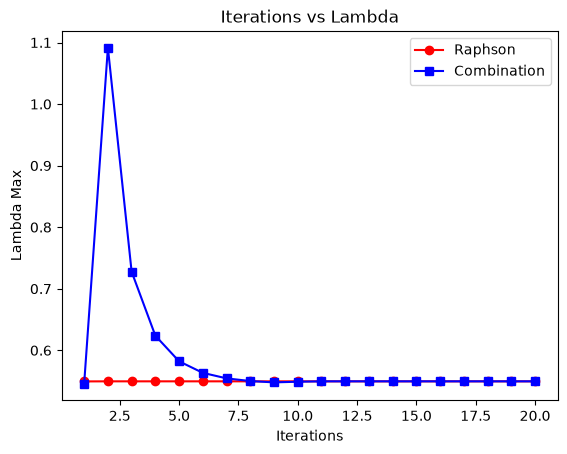

In [5]:
import matplotlib.pyplot as plt

itera = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
plt.plot(itera,lambda1, color = 'red', marker='o', label = 'Raphson')
plt.plot(itera,lambda2, color = 'blue', marker = 's', label = 'Combination')
plt.xlabel('Iterations')
plt.ylabel('Lambda Max')
plt.title('Iterations vs Lambda')
plt.legend()
plt.show()


Analytical lambda_max   = 0.5496186028414366 micro meter
Newton-Raphson          = 0.5496186028414365  (error 1.11e-16)
Bisection + Newton      = 0.5496186028414365  (error 1.11e-16)


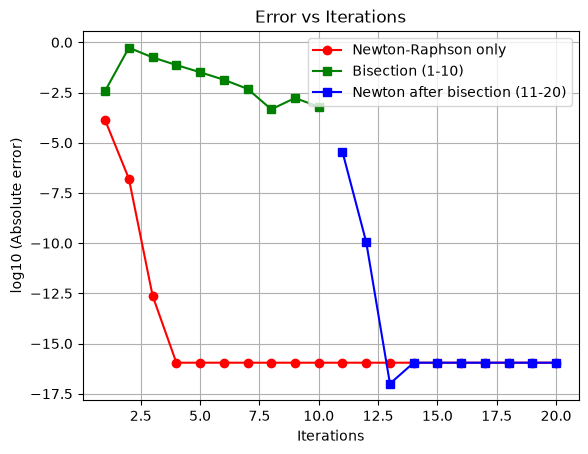

Bisection: error shrinks by about 0.56x per iteration -> linear (order 1)
Newton (alone):           order p = 2.00
Newton (after bisection): order p = 2.00


In [8]:
u_exact = 4.965114231744276
lam_exact = c2/(T*u_exact)
print(f"Analytical lambda_max   = {lam_exact} micro meter")
print(f"Newton-Raphson          = {lambda1[-1]}  (error {abs(lambda1[-1]-lam_exact):.2e})")
print(f"Bisection + Newton      = {lambda2[-1]}  (error {abs(lambda2[-1]-lam_exact):.2e})")
err1 = np.maximum(np.abs(np.array(lambda1) - lam_exact), 1e-17)   
err2 = np.maximum(np.abs(np.array(lambda2) - lam_exact), 1e-17)
itera = np.arange(1, 21)

plt.plot(itera, np.log10(err1), marker = 'o', color='red', label='Newton-Raphson only')
plt.plot(itera[:10], np.log10(err2[:10]), marker = 's', color='green', label='Bisection (1-10)')
plt.plot(itera[10:], np.log10(err2[10:]), marker = 's', color='blue', label='Newton after bisection (11-20)')
plt.xlabel('Iterations')
plt.ylabel('log10 (Absolute error)')
plt.title('Error vs Iterations')
plt.legend()
plt.grid(True)
plt.show()

slope = np.polyfit(itera[:10], np.log10(err2[:10]), 1)[0]
print(f"Bisection: error shrinks by about {10**slope:.2f}x per iteration -> linear (order 1)")

p_newton = np.log(err1[2]/err1[1]) / np.log(err1[1]/err1[0])
p_comb   = np.log(err2[11]/err2[10]) / np.log(err2[10]/err2[9])
print(f"Newton (alone):           order p = {p_newton:.2f}")
print(f"Newton (after bisection): order p = {p_comb:.2f}")